<a href="https://colab.research.google.com/github/cybersifat/ML-Project/blob/main/260052_Housing_Price_Analysis_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Housing Price Analysis and Prediction
### Data Analysis & Machine Learning Project

**Dataset:** `Housing.csv` — 545 residential properties described by size, room counts and a set of yes/no facilities.

---

## 1. Problem Definition

### The real-world problem

When a house is put on the market, the seller, the buyer and the estate agent all have to agree on a number. In practice that number is usually guessed from "similar houses sold nearby", which is slow, inconsistent and easy to get wrong. An agency that prices a property too high leaves it unsold for months; too low and the owner loses a large amount of money.

### Objective

Using historical data on 545 sold houses, we want to answer two questions:

1. **Regression question:** Given the physical characteristics of a house (plot area, bedrooms, bathrooms, stories, parking, and facilities such as air conditioning or a preferred location), can we estimate its **price**?
2. **Which characteristics matter most?** If air conditioning adds more value than an extra bedroom, that is directly useful to a property developer deciding where to spend the renovation budget.

The target variable is `price`, which is a continuous numerical value. Therefore the natural machine learning task here is **Regression**. Later, in the bonus task, we convert the same problem into a **Classification** task (affordable vs. premium housing).

### Why this is useful

* An estate agency gets a fast, consistent first estimate instead of relying only on personal judgement.
* A buyer can check whether an asking price is reasonable for what the house actually offers.
* A developer learns which improvements (an extra bathroom, air conditioning, a preferred neighbourhood) return the most value.

## 2. Importing Libraries

Before doing anything else we import the libraries we will use in the whole project. We keep the list short and standard: Pandas for handling the table, NumPy for numerical operations, Matplotlib and Seaborn for the charts, and the specific Scikit-learn tools for modelling and evaluation.

In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning - models
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Machine learning - evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

# Make the charts look consistent throughout the notebook
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Show numbers in a readable way instead of scientific notation
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


### Explanation

This cell only prepares the environment; it does not touch the data yet.

* `pandas` and `numpy` are used for loading and transforming the dataset.
* `matplotlib` and `seaborn` are used for all visualisations. `sns.set_style("whitegrid")` and the default figure size are set once here so that every later chart is readable and consistent, instead of repeating styling code in every plot.
* From Scikit-learn we import only what we actually need: `train_test_split` to separate training and testing data, `LinearRegression` for the main regression task, `LogisticRegression` for the bonus classification task, the two Random Forest models used as comparison models, and the metric functions used for evaluation.
* `pd.set_option("display.float_format", ...)` is important for this particular dataset because house prices are in the millions. Without it, Pandas would print values such as `4.766729e+06`, which is hard to read. With it, we see `4,766,729.00`.

## 3. Loading the Dataset

We now load the CSV file into a Pandas DataFrame and look at the first few rows. The purpose of this step is simply to confirm that the file was read correctly and to get a first impression of what a single record looks like.

> **Note for Google Colab:** upload `Housing.csv` using the file panel on the left (or `files.upload()`) before running the cell below.

In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
  print(f'User uploaded file "{filename}" with length {len(uploaded[filename])} bytes')


Saving Housing.csv to Housing (1).csv
User uploaded file "Housing (1).csv" with length 29981 bytes


In [ ]:
# Load the dataset into a DataFrame
df = pd.read_csv("Housing.csv")

# Display the first five records
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### Explanation

`pd.read_csv()` reads the file and stores it in a DataFrame called `df`, which behaves like a table with rows (houses) and columns (characteristics). `head()` displays the first five rows.

From this first look we can already see the structure of a record: `price` and `area` are large numbers, `bedrooms`, `bathrooms`, `stories` and `parking` are small counts, and several columns (`mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `prefarea`) contain the text values `yes`/`no`. `furnishingstatus` contains text categories such as `furnished`. This tells us immediately that we will have to convert text columns into numbers before machine learning.

## 4. Understanding the Dataset

Before cleaning anything, we need to know what we are dealing with: how many records there are, what the columns are called, which data type each column has, and how much memory it uses. This is the standard first inspection of any dataset.

In [ ]:
# Size of the dataset: (rows, columns)
print("Shape of the dataset:", df.shape)
print("Number of houses (rows):", df.shape[0])
print("Number of characteristics (columns):", df.shape[1])

print("\nColumn names:")
print(list(df.columns))

print("\nColumn data types and non-null counts:")
df.info()

Shape of the dataset: (545, 13)
Number of houses (rows): 545
Number of characteristics (columns): 13

Column names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Column data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking   

### Explanation

The dataset contains **545 rows and 13 columns**, so we have 545 houses described by 12 possible predictors plus the target `price`.

`df.info()` confirms two useful facts:

1. **Data types.** Six columns are stored as integers (`price`, `area`, `bedrooms`, `bathrooms`, `stories`, `parking`) and seven are stored as text/object (`mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `prefarea`, `furnishingstatus`). These types are already logically correct — numbers are numbers and categories are text — so no data type needs to be forced or repaired.
2. **Completeness.** Every column shows 545 non-null values, which is the first sign that there are no missing values. We verify this properly in the cleaning section.

The dataset is small (545 records). This is worth noting early because it limits how complex a model we can reasonably train, and we return to this point in the limitations section.

In [ ]:
# Descriptive statistics for the numerical columns
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,545.00,545.00,545.00,545.00,545.00,545.00
mean,"4,766,729.25","5,150.54",2.97,1.29,1.81,0.69
std,"1,870,439.62","2,170.14",0.74,0.50,0.87,0.86
min,"1,750,000.00","1,650.00",1.00,1.00,1.00,0.00
25%,"3,430,000.00","3,600.00",2.00,1.00,1.00,0.00
50%,"4,340,000.00","4,600.00",3.00,1.00,2.00,0.00
75%,"5,740,000.00","6,360.00",3.00,2.00,2.00,1.00
max,"13,300,000.00","16,200.00",6.00,4.00,4.00,3.00


### Explanation

`describe()` gives the count, mean, standard deviation, minimum, maximum and quartiles of every numerical column. Three things stand out and shape the rest of the analysis:

* **Price range is very wide.** The cheapest house is 1,750,000 and the most expensive is 13,300,000, with a mean of 4,766,729 and a median of 4,340,000. Because the **mean is higher than the median**, the price distribution is pulled to the right by a group of expensive houses — a first hint of right-skew that we confirm with a histogram later.
* **Area range is also wide**, from 1,650 to 16,200 square feet, with a median of 4,600.
* **Room counts are small and repetitive.** Bedrooms average around 3, bathrooms around 1, stories around 2 and parking around 0.7. Their minimum and maximum values (bedrooms 1–6, bathrooms 1–4, stories 1–4, parking 0–3) are all realistic. There are no impossible values such as 0 bedrooms or a negative area, which means the dataset does not contain obviously invalid records.

In [ ]:
# How many unique values does each column contain?
print("Unique values per column:")
print(df.nunique())

# For the text columns, what are those values exactly?
categorical_cols = df.select_dtypes(include="object").columns

print("\nCategories found in each text column:")
for col in categorical_cols:
    print(f"{col}: {list(df[col].unique())}")

Unique values per column:
price               219
area                284
bedrooms              6
bathrooms             4
stories               4
mainroad              2
guestroom             2
basement              2
hotwaterheating       2
airconditioning       2
parking               4
prefarea              2
furnishingstatus      3
dtype: int64

Categories found in each text column:
mainroad: ['yes', 'no']
guestroom: ['no', 'yes']
basement: ['no', 'yes']
hotwaterheating: ['no', 'yes']
airconditioning: ['yes', 'no']
prefarea: ['yes', 'no']
furnishingstatus: ['furnished', 'semi-furnished', 'unfurnished']


### Explanation

This check has a specific purpose: **to detect inconsistent categorical values** such as `Yes`, `yes` and `YES` being treated as three different categories, which is a very common problem in real data.

The result is reassuring. The six yes/no columns contain exactly two values each, always written in lowercase as `yes` and `no`. `furnishingstatus` contains exactly three values: `furnished`, `semi-furnished` and `unfurnished`. There are no spelling variations, no stray spaces and no unexpected extra categories, so **no category standardisation is needed**.

The unique-value counts also confirm that `bedrooms`, `bathrooms`, `stories` and `parking` take only a handful of distinct values (6, 4, 4 and 4 respectively). They are numeric, but they behave like ordered counts, which is why we will later analyse them with bar charts rather than histograms.

## 5. Data Cleaning

Cleaning means checking for and fixing four problems: missing values, duplicate records, wrong data types and invalid or impossible values. We check each one explicitly and explain the decision taken, even when the answer is "no action needed" — because knowing that the data is clean is itself a result that has to be demonstrated, not assumed.

In [ ]:
# 1. Missing values
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values in the dataset:", df.isnull().sum().sum())

Missing values per column:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Total missing values in the dataset: 0


### Explanation

`isnull().sum()` counts empty cells in each column. The result is **0 missing values in every column**, so the total is 0.

**Cleaning decision:** no imputation is performed. This is the right decision here — filling values with the mean or median when nothing is missing would artificially alter a complete dataset. Had there been missing values, the plan would have been to fill numerical columns with the median (safer than the mean because prices are skewed) and categorical columns with the most frequent category.

In [ ]:
# 2. Duplicate records
duplicate_count = df.duplicated().sum()
print("Number of fully duplicated rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed. New shape:", df.shape)
else:
    print("No duplicates found - the dataset is left unchanged.")

Number of fully duplicated rows: 0
No duplicates found - the dataset is left unchanged.


### Explanation

A duplicate row would mean the same house was recorded twice, which would give that house double weight during training and make the model's test score look better than it really is.

`df.duplicated().sum()` returns **0**, so there are no fully duplicated rows and nothing is removed. The `if` statement is written so that the notebook would still handle duplicates correctly if the dataset were updated later.

In [ ]:
# 3. Invalid or impossible values
print("Houses with area <= 0:", (df["area"] <= 0).sum())
print("Houses with price <= 0:", (df["price"] <= 0).sum())
print("Houses with 0 bedrooms:", (df["bedrooms"] <= 0).sum())
print("Houses with 0 bathrooms:", (df["bathrooms"] <= 0).sum())

print("\nValue counts for the small count columns:")
print("bedrooms :", df["bedrooms"].value_counts().sort_index().to_dict())
print("bathrooms:", df["bathrooms"].value_counts().sort_index().to_dict())
print("stories  :", df["stories"].value_counts().sort_index().to_dict())
print("parking  :", df["parking"].value_counts().sort_index().to_dict())

Houses with area <= 0: 0
Houses with price <= 0: 0
Houses with 0 bedrooms: 0
Houses with 0 bathrooms: 0

Value counts for the small count columns:
bedrooms : {1: 2, 2: 136, 3: 300, 4: 95, 5: 10, 6: 2}
bathrooms: {1: 401, 2: 133, 3: 10, 4: 1}
stories  : {1: 227, 2: 238, 3: 39, 4: 41}
parking  : {0: 299, 1: 126, 2: 108, 3: 12}


### Explanation

Here we look for values that are numerically possible but logically impossible, such as a house with a negative area or zero bedrooms.

There are **no non-positive prices or areas, and no houses with zero bedrooms or zero bathrooms**. The value counts show sensible distributions: most houses have 2–4 bedrooms (300 of them have exactly 3), 401 of the 545 houses have a single bathroom, and 299 houses have no parking space. A parking value of 0 is *not* invalid — it correctly means "no parking space" — so these rows are kept.

**Cleaning decision:** no rows are deleted for invalidity, because none of the records is logically impossible.

In [ ]:
# 4. Outlier detection using the IQR rule, applied to price and area
for col in ["price", "area"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"--- {col} ---")
    print(f"Q1 = {Q1:,.0f} | Q3 = {Q3:,.0f} | IQR = {IQR:,.0f}")
    print(f"Normal range: {lower:,.0f} to {upper:,.0f}")
    print(f"Number of outliers: {len(outliers)}\n")

# Look at the most expensive houses to judge whether they are errors or real houses
print("The five most expensive houses in the dataset:")
print(df.sort_values("price", ascending=False).head(5))

--- price ---
Q1 = 3,430,000 | Q3 = 5,740,000 | IQR = 2,310,000
Normal range: -35,000 to 9,205,000
Number of outliers: 15

--- area ---
Q1 = 3,600 | Q3 = 6,360 | IQR = 2,760
Normal range: -540 to 10,500
Number of outliers: 12

The five most expensive houses in the dataset:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
1  12250000  8960         4          4        4      yes        no       no   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
2              no              no        2      yes   semi-furnished  
1              no             yes     

### Explanation

The IQR rule flags any value further than 1.5 × IQR from the quartiles. It finds **15 outlier prices** (above 9,205,000) and **12 outlier areas** (above 10,500). Both sets are on the *high* side only.

Now the important part — **the decision**. Statistically flagged does not mean wrong. Looking at the five most expensive houses, they are large properties with several bathrooms, multiple stories, air conditioning and preferred locations. They are exactly what an expensive house should look like, so they are **genuine luxury properties, not recording errors**.

**Cleaning decision: the outliers are kept.** Two reasons:

1. Deleting 15 of 545 rows (about 3% of the data) would throw away the entire premium segment of the market. The model would then be unable to price expensive houses at all — and expensive houses are precisely the cases where a pricing mistake costs the most money.
2. They are consistent with the rest of the data rather than contradicting it.

We do, however, record this decision as a known cost: these high-priced houses are the hardest for a linear model to fit, and they are a major reason why the prediction error reported later is as large as it is. This is an honest trade-off, not an oversight.

In [ ]:
# Final confirmation that the dataset is ready for analysis
print("Final shape after cleaning:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())
print("Duplicates remaining:", df.duplicated().sum())

Final shape after cleaning: (545, 13)
Missing values remaining: 0
Duplicates remaining: 0


### Explanation

A short confirmation step. The dataset still has its original **545 rows and 13 columns**, with 0 missing values and 0 duplicates, because the cleaning investigation concluded that no rows had to be removed or repaired. The data is now ready for exploratory analysis.

## 6. Exploratory Data Analysis (EDA)

The goal of EDA is to understand the data *before* modelling: how the target behaves, how the numerical variables relate to it, and whether the categorical variables actually separate cheap houses from expensive ones. Each analysis below answers a specific question rather than being produced for its own sake.

In [ ]:
# Question 1: how is the target variable (price) distributed?
print("Statistics of the target variable (price):")
print(df["price"].describe())

print("\nMedian price :", f"{df['price'].median():,.0f}")
print("Mean price   :", f"{df['price'].mean():,.0f}")
print("Skewness     :", round(df["price"].skew(), 3))

Statistics of the target variable (price):
count          545.00
mean     4,766,729.25
std      1,870,439.62
min      1,750,000.00
25%      3,430,000.00
50%      4,340,000.00
75%      5,740,000.00
max     13,300,000.00
Name: price, dtype: float64

Median price : 4,340,000
Mean price   : 4,766,729
Skewness     : 1.212


### Explanation

We start with the target, because everything else in the project is judged against it.

The mean price (4,766,729) is clearly **higher than the median (4,340,000)**, and the skewness value is **+1.212**. A skewness above +1 indicates a strongly right-skewed distribution: most houses are clustered at the lower and middle price levels, while a smaller number of expensive houses stretch the upper tail as far as 13,300,000.

This matters for the modelling stage: linear regression assumes the errors are evenly spread, and a skewed target with a long upper tail usually means the model will be accurate for ordinary houses and less accurate for luxury ones. We test this expectation later against the real results.

In [ ]:
# Question 2: which numerical variables move together with price?
numerical_cols = ["price", "area", "bedrooms", "bathrooms", "stories", "parking"]

correlation_with_price = df[numerical_cols].corr()["price"].sort_values(ascending=False)
print("Correlation of each numerical variable with price:")
print(correlation_with_price.to_string(float_format=lambda v: f"{v:.3f}"))

Correlation of each numerical variable with price:
price       1.000
area        0.536
bathrooms   0.518
stories     0.421
parking     0.384
bedrooms    0.366


### Explanation

Correlation measures how strongly two numerical variables move together, on a scale from -1 to +1. We use it to get an early ranking of which features are likely to be useful predictors.

The results, in order:

| Feature | Correlation with price |
|---|---|
| area | 0.536 |
| bathrooms | 0.518 |
| stories | 0.421 |
| parking | 0.384 |
| bedrooms | 0.366 |

**Interpretation:** `area` is the strongest single numerical predictor, which matches ordinary intuition — bigger plots cost more. The genuinely interesting result is that **`bathrooms` (0.518) is almost as strong as area, and clearly stronger than `bedrooms` (0.366)**. In other words, the number of bathrooms tells us more about a house's price than the number of bedrooms does. A plausible reason is that adding a bathroom is expensive and signals a higher-quality build, whereas bedrooms can be created simply by dividing existing space.

All correlations are positive and moderate (0.36–0.54). None of them is close to 0.9, so no single feature explains price on its own — a multi-feature model is justified.

In [ ]:
# Question 3: do the categorical (yes/no) features separate cheap from expensive houses?
categorical_features = ["mainroad", "guestroom", "basement", "hotwaterheating",
                        "airconditioning", "prefarea", "furnishingstatus"]

for col in categorical_features:
    print(f"--- {col} ---")
    summary = df.groupby(col)["price"].agg(["count", "mean"])
    summary.columns = ["number of houses", "average price"]
    print(summary)
    print()

--- mainroad ---
          number of houses  average price
mainroad                                 
no                      77   3,398,904.55
yes                    468   4,991,777.33

--- guestroom ---
           number of houses  average price
guestroom                                 
no                      448   4,544,545.62
yes                      97   5,792,896.91

--- basement ---
          number of houses  average price
basement                                 
no                     354   4,509,965.93
yes                    191   5,242,615.18

--- hotwaterheating ---
                 number of houses  average price
hotwaterheating                                 
no                            520   4,728,593.15
yes                            25   5,559,960.00

--- airconditioning ---
                 number of houses  average price
airconditioning                                 
no                            373   4,191,939.68
yes                           172   6,013,220

### Explanation

For each categorical feature we compare the average price of each group. If the averages are far apart, the feature carries real information about price and should be kept for modelling; if they are almost identical, the feature is close to useless.

The differences in average price are:

| Feature | "no" group | "yes" group | Difference |
|---|---|---|---|
| airconditioning | 4,191,940 | 6,013,221 | **+1,821,281** |
| mainroad | 3,398,905 | 4,991,777 | +1,592,872 |
| prefarea | 4,425,299 | 5,879,046 | +1,453,747 |
| guestroom | 4,544,546 | 5,792,897 | +1,248,351 |
| hotwaterheating | 4,728,593 | 5,559,960 | +831,367 |
| basement | 4,509,966 | 5,242,615 | +732,649 |

For `furnishingstatus`, average prices fall in a clear order: **furnished 5,495,696 → semi-furnished 4,907,524 → unfurnished 4,013,831**.

**Interpretation:** every categorical feature separates the groups in the expected direction, so all of them are worth keeping. Air conditioning shows the largest gap — houses with AC cost on average about 1.8 million more. Two cautions, though: this is a *raw* comparison that ignores everything else, so part of that gap may simply be that air-conditioned houses also tend to be larger. And `hotwaterheating` has only **25 "yes" houses out of 545**, so its average is based on very few records and should not be trusted too far.

## 7. Data Visualization

We now visualise the relationships identified above. Each chart is chosen to match the type of variable being studied: histograms and box plots for the distribution of a numerical variable, scatter plots for numerical-vs-numerical relationships, box plots and bar charts for category-vs-price comparisons, and a heatmap for the overall correlation structure.

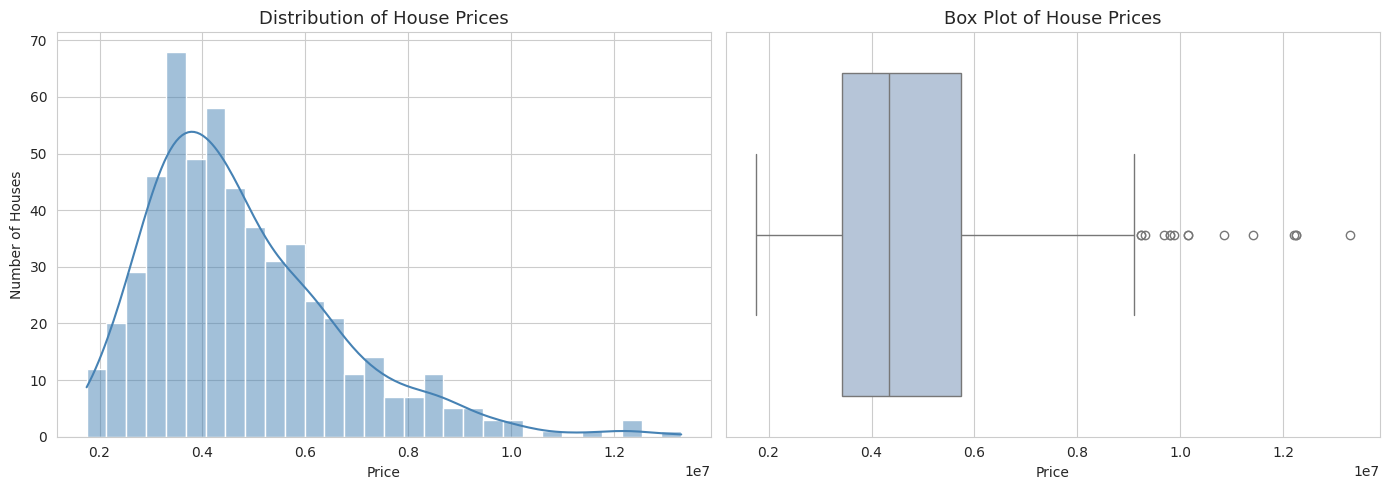

In [ ]:
# Distribution of the target variable: histogram + box plot side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: histogram showing the shape of the distribution
sns.histplot(df["price"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of House Prices", fontsize=13)
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Number of Houses")

# Right: box plot showing the median, spread and outliers
sns.boxplot(x=df["price"], ax=axes[1], color="lightsteelblue")
axes[1].set_title("Box Plot of House Prices", fontsize=13)
axes[1].set_xlabel("Price")

plt.tight_layout()
plt.show()

### Explanation

**What the graphs show.** The histogram on the left shows how many houses fall into each price range, and the box plot on the right summarises the same variable through its median, middle 50% and outliers.

**What pattern can be observed.** The histogram has a tall peak between roughly 3,000,000 and 5,000,000 and then a long tail stretching to the right, confirming the +1.212 skewness measured earlier. The box plot shows the box (the middle 50% of houses, from 3,430,000 to 5,740,000) sitting well to the left, with a series of individual points beyond the right whisker — these are the 15 expensive houses identified during cleaning.

**What this means for the real problem.** The market is dominated by mid-range housing, with a thin premium segment. Practically, this means an agency will have plenty of comparable examples when pricing an average house, but very few when pricing a luxury one. Our model will inherit exactly this weakness, because it learns from the same imbalance.

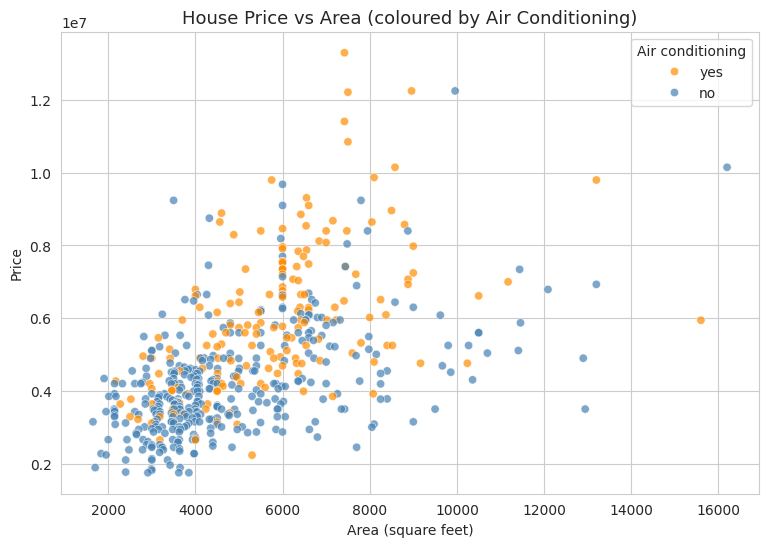

In [ ]:
# Relationship between area and price, split by air conditioning
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="area", y="price", hue="airconditioning",
                alpha=0.7, palette={"yes": "darkorange", "no": "steelblue"})
plt.title("House Price vs Area (coloured by Air Conditioning)", fontsize=13)
plt.xlabel("Area (square feet)")
plt.ylabel("Price")
plt.legend(title="Air conditioning")
plt.show()

### Explanation

We use a scatter plot because both `area` and `price` are continuous numerical variables, and it is the standard way to see whether one increases with the other. We colour the points by air conditioning so that two questions are answered in a single chart.

**What the graph shows.** Each dot is one house: its horizontal position is the plot area and its vertical position is the price.

**What pattern can be observed.** Three things:

1. There is a clear **upward trend** — larger houses generally cost more — but the points form a wide cloud rather than a tight line, which is exactly what a correlation of 0.536 looks like.
2. The spread **widens as area increases**. Small houses are priced fairly consistently, while large houses range from about 3,500,000 to over 13,000,000. Area alone therefore cannot pin down the price of a large house.
3. The orange points (air conditioning) sit noticeably **higher** than the blue points at the same area, which supports the price gap found in the EDA and shows it is not purely an effect of size.

**What this means for the real problem.** Size is the best starting point for a valuation, but for large properties it must be combined with quality features such as air conditioning. This is direct evidence that a multi-variable model will beat a rule of thumb based on area alone.

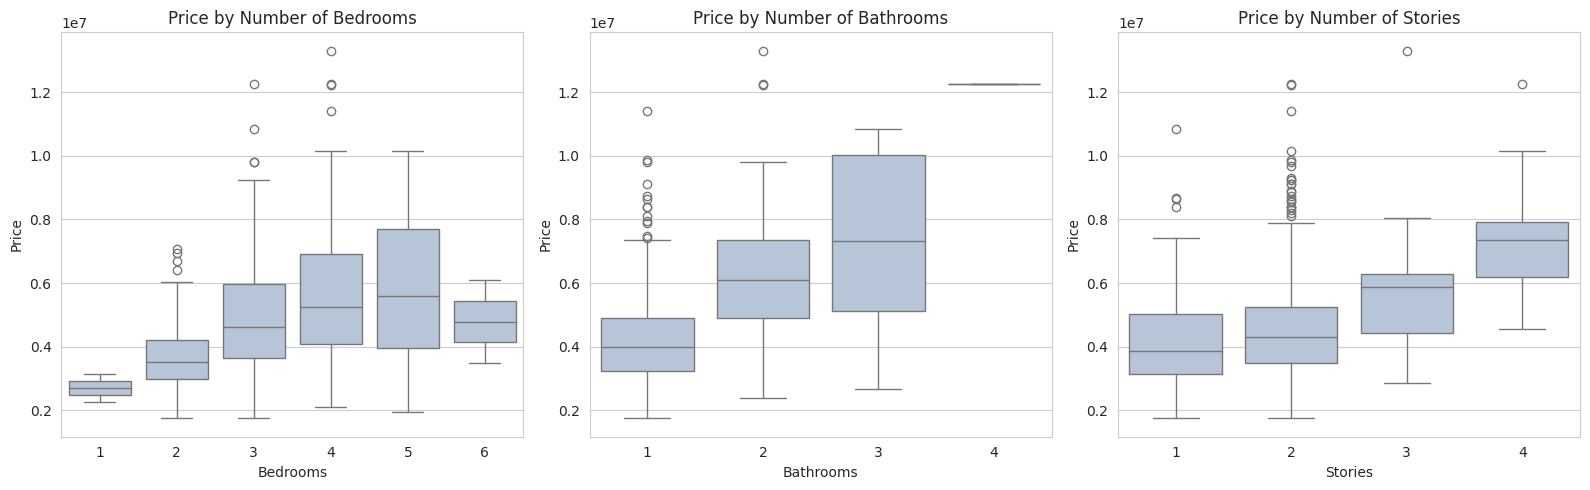

In [ ]:
# How price changes with the small count variables
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x="bedrooms", y="price", ax=axes[0], color="lightsteelblue")
axes[0].set_title("Price by Number of Bedrooms")
axes[0].set_xlabel("Bedrooms")
axes[0].set_ylabel("Price")

sns.boxplot(data=df, x="bathrooms", y="price", ax=axes[1], color="lightsteelblue")
axes[1].set_title("Price by Number of Bathrooms")
axes[1].set_xlabel("Bathrooms")
axes[1].set_ylabel("Price")

sns.boxplot(data=df, x="stories", y="price", ax=axes[2], color="lightsteelblue")
axes[2].set_title("Price by Number of Stories")
axes[2].set_xlabel("Stories")
axes[2].set_ylabel("Price")

plt.tight_layout()
plt.show()

### Explanation

Box plots are the right choice here because `bedrooms`, `bathrooms` and `stories` take only a few distinct values. A box plot shows the whole price distribution within each group, not just the average, so we can see both the trend and how reliable it is.

**What the graphs show.** For every room count, the box marks the middle 50% of prices and the line inside it marks the median.

**What pattern can be observed.** Prices rise as bathrooms and stories increase, and the increase for **bathrooms is the steepest and cleanest** — going from 1 to 2 bathrooms lifts the whole box substantially. Bedrooms show a rise from 2 to 4 but then become unstable, because there are only 10 houses with 5 bedrooms and 2 with 6 bedrooms; the boxes for those groups are based on too few houses to be meaningful.

**What this means for the real problem.** For a developer, the chart argues that **adding a bathroom is a more reliable way to raise value than adding a bedroom** — which is consistent with the correlation ranking (0.518 vs 0.366). It also warns us not to over-interpret predictions for unusually large houses, since the data barely covers them.

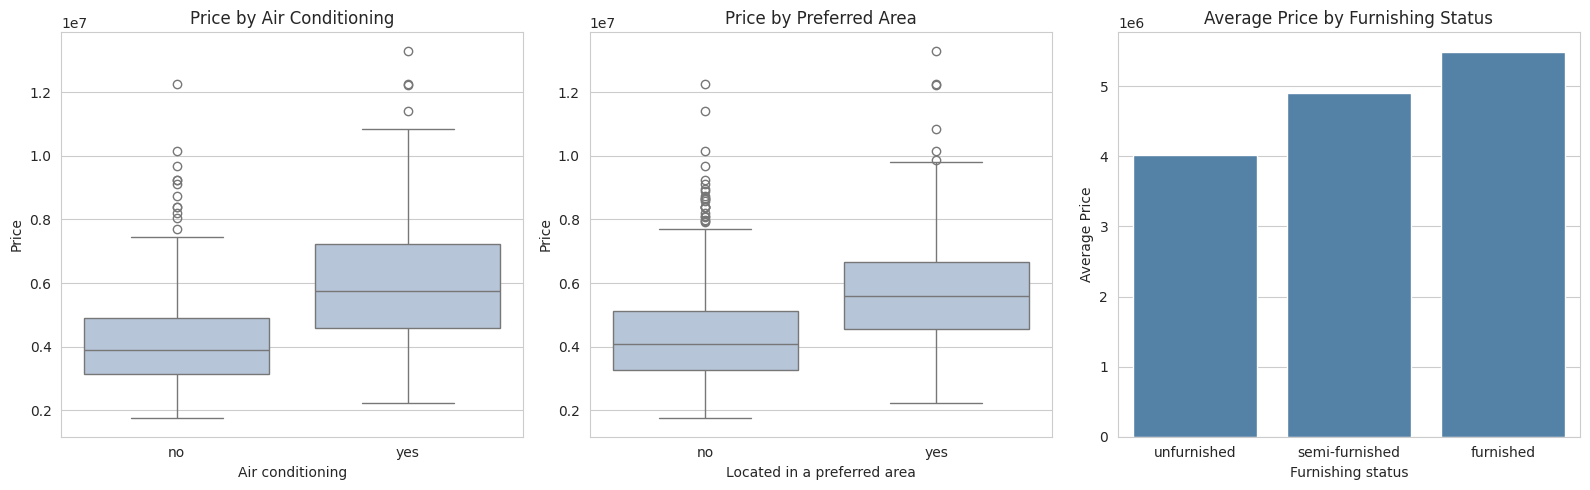

In [ ]:
# Effect of the categorical facilities on price
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x="airconditioning", y="price", ax=axes[0],
            order=["no", "yes"], color="lightsteelblue")
axes[0].set_title("Price by Air Conditioning")
axes[0].set_xlabel("Air conditioning")
axes[0].set_ylabel("Price")

sns.boxplot(data=df, x="prefarea", y="price", ax=axes[1],
            order=["no", "yes"], color="lightsteelblue")
axes[1].set_title("Price by Preferred Area")
axes[1].set_xlabel("Located in a preferred area")
axes[1].set_ylabel("Price")

sns.barplot(data=df, x="furnishingstatus", y="price", ax=axes[2],
            order=["unfurnished", "semi-furnished", "furnished"],
            color="steelblue", errorbar=None)
axes[2].set_title("Average Price by Furnishing Status")
axes[2].set_xlabel("Furnishing status")
axes[2].set_ylabel("Average Price")

plt.tight_layout()
plt.show()

### Explanation

We use box plots for the two yes/no features because we want to compare full distributions, and a bar chart for `furnishingstatus` because there the point of interest is the ordered progression of the averages.

**What the graphs show.** The price distribution of houses with and without air conditioning, with and without a preferred location, and the average price for each furnishing level.

**What pattern can be observed.** Houses with air conditioning have a visibly higher median and a box shifted upwards, matching the 1.8 million average gap. The same, slightly weaker, pattern appears for preferred area. The furnishing bar chart rises steadily from unfurnished to semi-furnished to furnished, so furnishing status behaves like an ordered scale rather than three unrelated labels. Note also that the "no" boxes still contain some expensive houses — no single feature is decisive on its own.

**What this means for the real problem.** These are the features an agency can actually list in an advertisement, and they demonstrably carry price information. For a developer, installing air conditioning is a comparatively cheap intervention linked to a large price difference — the single most actionable finding in the EDA.

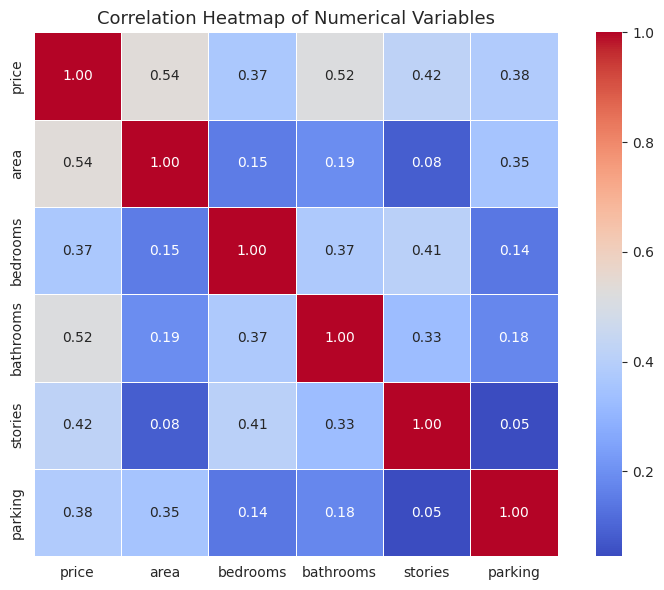

In [ ]:
# Correlation heatmap for the numerical variables
plt.figure(figsize=(8, 6))
correlation_matrix = df[numerical_cols].corr()

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm",
            fmt=".2f", square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Variables", fontsize=13)
plt.tight_layout()
plt.show()

### Explanation

The heatmap shows every pairwise correlation at once. We use it for two different purposes: to confirm which features relate to `price`, and — just as importantly — to check whether the *features themselves* are strongly correlated with each other.

**What the graph shows.** Red squares indicate positive correlation, blue indicates negative, and the number in each cell is the exact coefficient.

**What pattern can be observed.** The top row confirms the ranking already found (area 0.54, bathrooms 0.52, stories 0.42, parking 0.38, bedrooms 0.37). Among the features themselves, the strongest relationships are `bedrooms`–`stories` (0.41), `bedrooms`–`bathrooms` (0.37) and `area`–`parking` (0.35). All of these are **moderate, and none approaches the 0.8–0.9 level** that would signal serious multicollinearity.

**What this means for the real problem.** Because the features are not redundant copies of each other, we can safely put all of them into a linear regression and still interpret the coefficients sensibly. If, say, `area` and `bedrooms` had been correlated at 0.95, the model's coefficients would have become unstable and untrustworthy.

## 8. Feature Engineering

Machine learning models in Scikit-learn only accept numbers, so the seven text columns must be converted. We also consider whether any new feature is genuinely worth creating. The guiding rule is to keep the dataset simple and interpretable rather than adding complexity for its own sake.

In [ ]:
# Work on a copy so that the original cleaned data stays available for reference
data = df.copy()

# Convert the six yes/no columns into 1/0
binary_columns = ["mainroad", "guestroom", "basement",
                  "hotwaterheating", "airconditioning", "prefarea"]

for col in binary_columns:
    data[col] = data[col].map({"yes": 1, "no": 0})

print("Binary columns after encoding:")
print(data[binary_columns].head())

Binary columns after encoding:
   mainroad  guestroom  basement  hotwaterheating  airconditioning  prefarea
0         1          0         0                0                1         1
1         1          0         0                0                1         0
2         1          0         1                0                0         1
3         1          0         1                0                1         1
4         1          1         1                0                1         0


### Explanation

Each yes/no column has exactly two categories, so the simplest correct encoding is to map `yes` to 1 and `no` to 0. This creates no extra columns and keeps interpretation direct: in the regression model, the coefficient of `airconditioning` will read as "the extra price associated with having air conditioning, holding everything else constant".

We work on a copy called `data` so that `df` remains in its cleaned, human-readable form in case we want to plot or check something later.

In [ ]:
# Create one derived feature: average area per bedroom
data["area_per_bedroom"] = (data["area"] / data["bedrooms"]).round(2)

print(data[["area", "bedrooms", "area_per_bedroom"]].head())
print("\nCorrelation of area_per_bedroom with price:",
      round(data["area_per_bedroom"].corr(data["price"]), 3))
print("Correlation of area alone with price:",
      round(data["area"].corr(data["price"]), 3))

   area  bedrooms  area_per_bedroom
0  7420         4          1,855.00
1  8960         4          2,240.00
2  9960         3          3,320.00
3  7500         4          1,875.00
4  7420         4          1,855.00

Correlation of area_per_bedroom with price: 0.245
Correlation of area alone with price: 0.536


### Explanation

We create exactly **one** derived feature, and only because there is a concrete reason for it. Two houses can have the same total area and the same number of bedrooms but feel very different: 4,000 sq ft split into 3 bedrooms gives spacious rooms, while 4,000 sq ft split into 6 bedrooms gives cramped ones. Neither `area` nor `bedrooms` alone captures that idea of spaciousness, so `area / bedrooms` expresses something the model cannot otherwise see.

Its correlation with price is **0.245**, which is positive but weaker than `area` on its own (0.536). That is not a reason to discard it — a derived feature is meant to add information alongside the originals rather than replace them — but it does set a modest expectation. **We test explicitly in Section 10 whether this feature actually improves the model**, and we report the honest answer instead of assuming it helped.

No other derived features are created. Ratios such as bathrooms-per-bedroom could be invented, but the assignment rightly warns against engineering features purely to look sophisticated.

In [ ]:
# Encode furnishingstatus, which has three categories, using one-hot encoding
data = pd.get_dummies(data, columns=["furnishingstatus"], drop_first=True)

# Convert the True/False columns produced by get_dummies into 1/0
dummy_columns = ["furnishingstatus_semi-furnished", "furnishingstatus_unfurnished"]
for col in dummy_columns:
    data[col] = data[col].astype(int)

print("Columns after encoding:")
print(list(data.columns))
print("\nShape of the prepared dataset:", data.shape)
data.head()

Columns after encoding:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'area_per_bedroom', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']

Shape of the prepared dataset: (545, 15)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,area_per_bedroom,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,"1,855.00",0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,"2,240.00",0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,"3,320.00",1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,"1,875.00",0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,"1,855.00",0,0


### Explanation

`furnishingstatus` has three categories, so a single 0/1/2 column would force the model to assume the gaps between the levels are equal, which we have no evidence for. Instead we use **one-hot encoding**, which creates a separate 0/1 column for each category.

`drop_first=True` removes one of the three columns to avoid the dummy variable trap (if a house is neither semi-furnished nor unfurnished, it must be furnished, so the third column carries no new information and would make the linear model's coefficients unstable). The dropped category, **`furnished`, becomes the reference level**: the coefficients of the two remaining columns will be read as "compared to a furnished house".

After encoding, the dataset has **545 rows and 15 columns** (13 original + 1 derived + 1 extra from one-hot encoding) and contains only numbers.

In [ ]:
# Separate the features (X) from the target (y)
X = data.drop("price", axis=1)
y = data["price"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)
print("\nFeatures used for prediction:")
for i, col in enumerate(X.columns, start=1):
    print(f"{i}. {col}")

Features (X) shape: (545, 14)
Target (y) shape: (545,)

Features used for prediction:
1. area
2. bedrooms
3. bathrooms
4. stories
5. mainroad
6. guestroom
7. basement
8. hotwaterheating
9. airconditioning
10. parking
11. prefarea
12. area_per_bedroom
13. furnishingstatus_semi-furnished
14. furnishingstatus_unfurnished


### Explanation

`X` contains the 14 characteristics used to make a prediction, and `y` contains the value we want to predict (`price`).

**Which features are kept, and why.** All of them are kept, and this is a deliberate decision rather than laziness:

* `area`, `bathrooms`, `stories`, `parking`, `bedrooms` — all showed positive correlations with price between 0.37 and 0.54 in the EDA.
* `airconditioning`, `mainroad`, `prefarea`, `guestroom`, `basement`, `hotwaterheating` — all showed clear average price gaps between their groups.
* `furnishingstatus` dummies — the averages rise consistently across the three levels.
* `area_per_bedroom` — the derived feature, on trial and tested in Section 10.

**No features are removed**, because this dataset has no ID column, no timestamp and no obviously irrelevant field — every column describes a property characteristic that a buyer would reasonably care about. This is unusual and worth stating: many datasets contain junk columns, but this one does not.

## 9. Machine Learning — Regression

The target `price` is a continuous numerical value that can take any amount within a wide range, so this is a **regression** problem, not a classification one. We train a **Linear Regression** model as the main model because it is simple, fast and — most valuable for this project — its coefficients can be read directly as the money value of each characteristic. We then compare it with a Random Forest to check whether a more flexible model does better.

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape[0], "houses")
print("Testing set :", X_test.shape[0], "houses")

Training set: 436 houses
Testing set : 109 houses


### Explanation

We split the 545 houses into **436 for training (80%)** and **109 for testing (20%)**.

The reason for splitting is fundamental: a model that is judged on the same data it learned from can simply memorise those houses and appear excellent while being useless on new ones. The test set is kept completely unseen during training so that it acts as a fair simulation of "a house the agency has never valued before".

`random_state=42` fixes the random shuffling so that anyone re-running this notebook gets exactly the same split and therefore exactly the same results reported below.

In [ ]:
# Train the Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict prices for the unseen test houses
y_pred = linear_model.predict(X_test)

# Compare the first five real prices with the predicted ones
comparison = pd.DataFrame({
    "Actual Price": y_test.values[:5],
    "Predicted Price": y_pred[:5].round(0)
})
comparison["Difference"] = comparison["Actual Price"] - comparison["Predicted Price"]
print(comparison)

   Actual Price  Predicted Price    Difference
0       4060000     5,158,352.00 -1,098,352.00
1       6650000     7,238,567.00   -588,567.00
2       3710000     3,117,826.00    592,174.00
3       6440000     4,644,824.00  1,795,176.00
4       2800000     3,345,298.00   -545,298.00


### Explanation

`fit()` is the actual learning step: the model finds the combination of weights that minimises the total squared error on the 436 training houses. `predict()` then applies those weights to the 109 test houses.

The comparison table shows the first five test houses with their real price, the model's estimate and the difference. Some estimates land close to the true value while others are off by a substantial amount — which is exactly why we now measure the error formally across all 109 test houses rather than judging from five examples.

In [ ]:
# Inspect what the model learned: the coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_.round(2)
}).sort_values("Coefficient", ascending=False)

print("Intercept:", round(linear_model.intercept_, 2))
print("\nCoefficients (effect on price of a one-unit increase):")
print(coefficients.to_string(index=False))

Intercept: 860699.09

Coefficients (effect on price of a one-unit increase):
                        Feature  Coefficient
                      bathrooms 1,082,904.00
                airconditioning   795,622.48
                hotwaterheating   699,025.02
                       prefarea   617,761.23
                        stories   393,505.70
                       basement   386,736.85
                       mainroad   363,355.54
                        parking   222,181.47
                      guestroom   215,831.17
                           area       343.80
               area_per_bedroom      -310.96
                       bedrooms  -102,048.83
furnishingstatus_semi-furnished  -139,353.09
   furnishingstatus_unfurnished  -425,641.31


### Explanation

A linear regression coefficient answers: "if this feature increases by one unit and everything else stays the same, how much does the predicted price change?" This is where the model becomes genuinely useful to a business, not just a prediction machine.

The main results:

| Feature | Coefficient | Reading |
|---|---|---|
| bathrooms | +1,082,904 | one extra bathroom ≈ +1.08 million |
| airconditioning | +795,622 | having AC ≈ +796 thousand |
| hotwaterheating | +699,025 | ≈ +699 thousand (only 25 such houses — unreliable) |
| prefarea | +617,761 | preferred location ≈ +618 thousand |
| stories | +393,506 | one extra storey ≈ +394 thousand |
| basement | +386,737 | ≈ +387 thousand |
| mainroad | +363,356 | ≈ +363 thousand |
| parking | +222,181 | one extra parking space ≈ +222 thousand |
| guestroom | +215,831 | ≈ +216 thousand |
| area | +343.80 | each extra square foot ≈ +344 |
| bedrooms | **−102,049** | one extra bedroom ≈ −102 thousand |
| furnishingstatus_unfurnished | −425,641 | unfurnished ≈ 426 thousand less than furnished |

Two results deserve comment.

**`area` looks tiny (+343.80) but is not.** It is measured per square foot, so a house 1,000 sq ft larger is predicted to cost about 343,800 more. Coefficients can only be compared fairly between features measured on the same scale.

**`bedrooms` is negative, which looks wrong at first.** In the EDA, bedrooms correlated *positively* with price (+0.366). The explanation is that the coefficient holds everything else fixed: it says that taking a house of a *given total area* and dividing it into one more bedroom slightly reduces its value — smaller rooms in the same space. That is economically sensible, and it also shows why raw correlations and model coefficients answer different questions.

In [ ]:
# Compare with a Random Forest to see whether a more flexible model does better
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Linear Regression R2:", round(r2_score(y_test, y_pred), 4))
print("Random Forest    R2:", round(r2_score(y_test, rf_pred), 4))

# The Random Forest can rank feature importance, which linear regression cannot do directly
importances = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_.round(4)
}).sort_values("Importance", ascending=False)

print("\nFeature importance according to the Random Forest:")
print(importances.head(8).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

Linear Regression R2: 0.6544
Random Forest    R2: 0.619

Feature importance according to the Random Forest:
                     Feature  Importance
                        area      0.4395
                   bathrooms      0.1493
            area_per_bedroom      0.0799
             airconditioning      0.0568
                     stories      0.0511
                     parking      0.0511
furnishingstatus_unfurnished      0.0355
                    basement      0.0297


### Explanation

A Random Forest builds many decision trees and averages them. It can capture curved relationships and interactions that a straight-line model cannot, so it is a fair test of whether linear regression is too simple for this data.

**The result is that it is not.** Linear Regression scores **R² = 0.6544** while the Random Forest scores **R² = 0.6190** — the more complex model is actually *worse* on the test set. The most likely reason is the dataset size: with only 436 training houses, a forest of deep trees fits patterns in the training data that do not carry over to new houses. This is a real, if slightly unglamorous, finding, and it justifies keeping the simpler and more explainable Linear Regression as our main model.

The Random Forest is still useful for one thing: it ranks feature importance. Its top features are **area (0.4395), bathrooms (0.1493), area_per_bedroom (0.0799), airconditioning (0.0568), parking (0.0511) and stories (0.0511)**. This is an independent confirmation of the EDA — size and bathrooms dominate, with air conditioning the strongest of the facility features.

## 10. Model Evaluation

We now measure how wrong the model is on the 109 unseen test houses, using the four standard regression metrics. All values below are produced by running the code — none are typed in by hand.

In [ ]:
# Calculate all four regression metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("REGRESSION EVALUATION (Linear Regression, 109 unseen test houses)")
print("-" * 60)
print(f"MAE  (Mean Absolute Error) : {mae:,.2f}")
print(f"MSE  (Mean Squared Error)  : {mse:,.2f}")
print(f"RMSE (Root Mean Sq. Error) : {rmse:,.2f}")
print(f"R2   (R-squared Score)     : {r2:.4f}")

# Put the error in context by comparing it with the average test price
print("-" * 60)
print(f"Average actual price in the test set: {y_test.mean():,.2f}")
print(f"MAE as a percentage of that average : {mae / y_test.mean() * 100:.2f}%")

# Compare training and test performance to check for overfitting
print(f"\nR2 on training data: {linear_model.score(X_train, y_train):.4f}")
print(f"R2 on test data    : {r2:.4f}")

REGRESSION EVALUATION (Linear Regression, 109 unseen test houses)
------------------------------------------------------------
MAE  (Mean Absolute Error) : 968,361.67
MSE  (Mean Squared Error)  : 1,746,733,613,627.92
RMSE (Root Mean Sq. Error) : 1,321,640.50
R2   (R-squared Score)     : 0.6544
------------------------------------------------------------
Average actual price in the test set: 5,007,536.70
MAE as a percentage of that average : 19.34%

R2 on training data: 0.6876
R2 on test data    : 0.6544


### Explanation of each metric and of the actual results

**MAE = 968,361.67.** The Mean Absolute Error is the average size of the mistake, ignoring direction. In plain language: *when this model values a house, it is off by about 968,000 on average.* Since the average test house costs 5,007,537, that is an error of **19.34%** — roughly one fifth of the price.

**MSE = 1,746,733,613,627.92.** The Mean Squared Error averages the *squared* mistakes. The number is astronomically large simply because prices in the millions become trillions when squared, so it should not be read as money. Its purpose is that squaring punishes large mistakes much more than small ones, making it useful for comparing models.

**RMSE = 1,321,640.50.** The Root Mean Squared Error takes the square root of MSE, returning to price units. It is meaningfully **larger than the MAE (1,321,640 vs 968,362)**, and that gap is itself informative: it means the errors are not evenly sized. A number of houses are predicted very badly, dragging RMSE up — almost certainly the expensive houses in the right tail we identified during cleaning.

**R² = 0.6544.** R-squared is the share of the variation in price the model explains, from 0 (no better than always guessing the average) to 1 (perfect). Our model explains **about 65% of why house prices differ**, leaving 35% unexplained.

### Is this a good model?

**Reasonably good, but not good enough to use unsupervised.** In its favour: 65% of price variation explained from only 12 basic characteristics is a genuine result, and the training R² (0.6876) is very close to the test R² (0.6544), so the model is **not overfitting** — it performs almost as well on new houses as on the ones it learned from. That is a healthy, stable model.

Against it: an average error of 19% is too large for a final valuation. On a 5,000,000 house, being wrong by nearly a million is the difference between a fast sale and a listing nobody views.

### Limitations of this model specifically

1. **The most important variable is missing: location.** We know only whether a house is in a "preferred area" — a single yes/no. In reality, the neighbourhood, school district and distance to the city centre explain an enormous share of house prices. Much of our unexplained 35% is almost certainly location.
2. **No age, condition or renovation data.** A newly renovated house and a run-down house with identical layouts are indistinguishable to this model.
3. **Linear assumption.** The model assumes each feature adds a fixed amount of money regardless of context, but in practice air conditioning probably adds more to a large house than a small one.
4. **Uneven errors.** The RMSE-vs-MAE gap shows expensive houses are predicted worst, exactly where accuracy matters most.
5. **No time dimension.** The dataset has no sale dates, so market movements and inflation cannot be accounted for.

In [ ]:
# Was the derived feature area_per_bedroom actually worth creating?
X_without = X.drop(columns=["area_per_bedroom"])
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_without, y, test_size=0.2, random_state=42
)

model_without = LinearRegression()
model_without.fit(X_train_w, y_train_w)
pred_without = model_without.predict(X_test_w)

print("WITH    area_per_bedroom -> R2:", round(r2, 4), "| MAE:", f"{mae:,.2f}")
print("WITHOUT area_per_bedroom -> R2:", round(r2_score(y_test_w, pred_without), 4),
      "| MAE:", f"{mean_absolute_error(y_test_w, pred_without):,.2f}")

WITH    area_per_bedroom -> R2: 0.6544 | MAE: 968,361.67
WITHOUT area_per_bedroom -> R2: 0.6529 | MAE: 970,043.40


### Explanation

This is an honesty check on our own feature engineering. We retrain the identical model on the identical split with the derived feature removed and compare.

**The result: R² = 0.6544 with the feature, R² = 0.6529 without it.** The improvement is **0.0015 — essentially nothing.** MAE also barely moves (968,362 vs 970,043).

**Conclusion:** `area_per_bedroom` does not harm the model, but it does not help it either, because the information it carries is already contained in `area` and `bedrooms`, which are both already in the model. We keep it (it costs nothing and the Random Forest did rank it third in importance), but we report honestly that **it was not the improvement we hoped for**. This is worth stating plainly rather than hiding: adding cleverer features is not automatically the way to improve a model — in this case the missing ingredient is better *data*, especially location, not more transformations of the data we already have.

## 11. Real-World Prediction

Finally we use the trained model the way an estate agency would: a new house arrives, we enter its characteristics, and the model returns an estimated price.

In [ ]:
# A new house that has just come onto the market
new_house = pd.DataFrame([{
    "area": 6000,
    "bedrooms": 3,
    "bathrooms": 2,
    "stories": 2,
    "mainroad": 1,                          # yes - on a main road
    "guestroom": 0,                         # no guest room
    "basement": 1,                          # yes - has a basement
    "hotwaterheating": 0,                   # no hot water heating
    "airconditioning": 1,                   # yes - air conditioned
    "parking": 1,                           # 1 parking space
    "prefarea": 1,                          # yes - preferred area
    "area_per_bedroom": 6000 / 3,           # derived feature, calculated the same way
    "furnishingstatus_semi-furnished": 1,   # semi-furnished
    "furnishingstatus_unfurnished": 0
}])

# Keep the columns in exactly the same order the model was trained on
new_house = new_house[X.columns]

predicted_price = linear_model.predict(new_house)[0]

print("NEW HOUSE FOR VALUATION")
print("-" * 45)
print("Area              : 6,000 sq ft")
print("Bedrooms          : 3")
print("Bathrooms         : 2")
print("Stories           : 2")
print("Air conditioning  : yes")
print("Preferred area    : yes")
print("Furnishing        : semi-furnished")
print("-" * 45)
print(f"PREDICTED PRICE   : {predicted_price:,.2f}")
print(f"Expected error    : about +/- {mae:,.0f} (the model's MAE)")

NEW HOUSE FOR VALUATION
---------------------------------------------
Area              : 6,000 sq ft
Bedrooms          : 3
Bathrooms         : 2
Stories           : 2
Air conditioning  : yes
Preferred area    : yes
Furnishing        : semi-furnished
---------------------------------------------
PREDICTED PRICE   : 7,194,554.77
Expected error    : about +/- 968,362 (the model's MAE)


### Explanation

We build one new record with the same 14 columns, in the same order, and encoded the same way as the training data — this matters, because feeding the columns in a different order would silently produce a meaningless prediction.

**The model predicts a price of 7,194,554.77** for this house.

**In real-world language:** a 6,000 sq ft, 3-bedroom, 2-bathroom, 2-storey house that is air conditioned, has a basement, sits on a main road in a preferred area and comes semi-furnished should be listed at roughly **7.2 million**. That is well above the dataset median of 4,340,000, which is what we would expect: the house is larger than average and has almost every premium facility that the analysis identified as valuable.

**How an agency should use this number.** Not as the asking price, but as a **starting point with a stated margin**. Given the model's MAE of about 968,000, the honest advice is "this house is likely worth somewhere between roughly 6.2 and 8.2 million — now inspect the property and check the specific neighbourhood to narrow it down". A model that reports its own uncertainty is far more useful, and far safer, than one that presents a single confident figure.

## 12. Bonus Task — Converting Regression into Classification

### Why convert the problem?

Estimating an exact price is not always what a business needs. An estate agency often wants a faster and more robust decision: **is this an affordable-segment property or a premium one?** The two segments are marketed differently, shown to different buyers and handled by different sales teams. Getting the *segment* right is easier and more reliable than getting the exact number right.

### How the target is transformed

We convert the continuous `price` into two categories using the **median price** as the threshold:

* **0 = Low / affordable segment** → price ≤ median
* **1 = High / premium segment** → price > median

### Why the median and not the mean

This choice is deliberate. Recall from the EDA that price is right-skewed (skewness +1.212), which pulls the **mean (4,766,729) above the median (4,340,000)**. If we split at the mean, the expensive tail would push the threshold upward and produce clearly unbalanced groups. Splitting at the median guarantees an almost perfectly **balanced 50/50 split**, which is important because accuracy is misleading on imbalanced data — a model can score 90% simply by always predicting the majority class. A balanced split makes every metric we report honest and easy to interpret.

In [ ]:
# Create the binary target from the median price
median_price = data["price"].median()
print(f"Median price used as the threshold: {median_price:,.0f}")

data["price_category"] = (data["price"] > median_price).astype(int)

print("\nNumber of houses in each category:")
print(data["price_category"].value_counts().sort_index())
print("\n0 = Low / affordable segment, 1 = High / premium segment")

# Confirm the split is balanced
print("\nPercentage in each class:")
print((data["price_category"].value_counts(normalize=True) * 100).round(2))

Median price used as the threshold: 4,340,000

Number of houses in each category:
price_category
0    275
1    270
Name: count, dtype: int64

0 = Low / affordable segment, 1 = High / premium segment

Percentage in each class:
price_category
0   50.46
1   49.54
Name: proportion, dtype: float64


### Explanation

The comparison `data["price"] > median_price` produces True/False, and `.astype(int)` turns that into 1/0.

The result is **275 houses in the Low category and 270 in the High category** — a 50.46% / 49.54% split. This is as balanced as it is possible to get, and it is a direct consequence of using the median. (The slight imbalance exists only because several houses sit exactly at the median value and fall into the "Low" side of the comparison.)

Note that this transformation loses information: a house at 4,340,001 and a house at 13,300,000 are now both simply "High". That is the accepted trade-off — we give up precision to gain a decision that is easier to make correctly.

In [ ]:
# Prepare features and the new categorical target
# price is dropped as well - keeping it would let the model see the answer
X_class = data.drop(["price", "price_category"], axis=1)
y_class = data["price_category"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class, y_class, test_size=0.2, random_state=42, stratify=y_class
)

print("Training set:", X_train_c.shape[0], "houses")
print("Testing set :", X_test_c.shape[0], "houses")
print("\nClass balance in the test set:")
print(y_test_c.value_counts().sort_index())

Training set: 436 houses
Testing set : 109 houses

Class balance in the test set:
price_category
0    55
1    54
Name: count, dtype: int64


### Explanation

Two details in this cell matter a great deal.

**We drop `price` as well as `price_category`.** If `price` stayed in the features, the model would achieve 100% accuracy instantly — the category was calculated *from* price, so it would simply be reading the answer. This mistake is called data leakage and it is one of the most common ways a machine learning project produces impressive but worthless results.

**We add `stratify=y_class`.** This forces the training and test sets to keep the same proportion of Low and High houses as the full dataset. The test set ends up with **55 Low and 54 High houses** out of 109 — nicely balanced, so our accuracy figure will be meaningful.

In [ ]:
# Train a Logistic Regression classifier
# StandardScaler is included because area values (thousands) and 0/1 flags
# are on completely different scales, which slows down logistic regression
classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
classifier.fit(X_train_c, y_train_c)

# Predict the segment of the unseen test houses
y_pred_class = classifier.predict(X_test_c)

print("First 15 predictions vs actual values:")
print("Predicted:", y_pred_class[:15])
print("Actual   :", y_test_c.values[:15])

First 15 predictions vs actual values:
Predicted: [1 1 0 0 0 1 0 0 0 0 0 0 0 1 1]
Actual   : [1 1 0 1 0 1 0 0 1 0 0 0 0 0 1]


### Explanation

We choose **Logistic Regression** because it is the classification counterpart of the linear model we already used and it is easy to explain: it estimates the probability that a house belongs to the premium segment and assigns it to that class when the probability exceeds 50%.

`StandardScaler` is placed in front of it in a pipeline. Scaling is needed because `area` runs into the thousands while the yes/no features are 0 or 1; without scaling, logistic regression converges slowly and treats the features unfairly. Putting both steps in a `make_pipeline` guarantees the scaling learned on the training data is applied identically to the test data, which prevents another subtle form of leakage.

Comparing the first 15 predictions with the actual values, most match — but a formal evaluation follows immediately.

## 13. Classification Evaluation

We now evaluate the classifier with a confusion matrix and the four standard classification metrics. As before, every number is produced by the code.

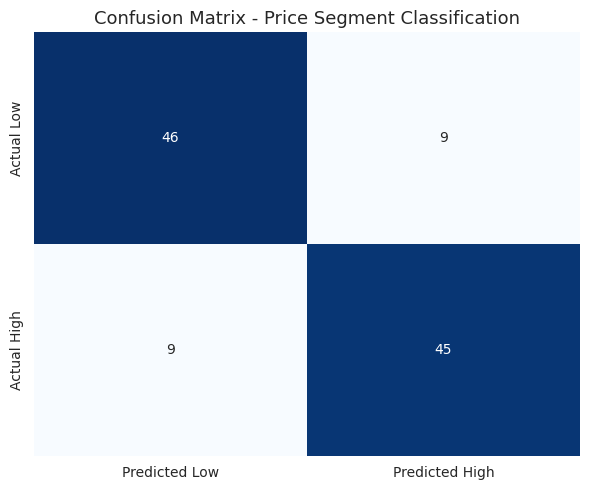

Confusion matrix values:
[[46  9]
 [ 9 45]]

True Negatives  (Low correctly identified) : 46
False Positives (Low predicted as High)    : 9
False Negatives (High predicted as Low)    : 9
True Positives  (High correctly identified): 45


In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test_c, y_pred_class)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted Low", "Predicted High"],
            yticklabels=["Actual Low", "Actual High"])
plt.title("Confusion Matrix - Price Segment Classification", fontsize=13)
plt.tight_layout()
plt.show()

print("Confusion matrix values:")
print(cm)
print("\nTrue Negatives  (Low correctly identified) :", cm[0, 0])
print("False Positives (Low predicted as High)    :", cm[0, 1])
print("False Negatives (High predicted as Low)    :", cm[1, 0])
print("True Positives  (High correctly identified):", cm[1, 1])

### Explanation

The confusion matrix shows exactly which kinds of mistakes the model makes, which a single accuracy number hides.

Out of the 109 test houses:

* **46 affordable houses correctly identified as affordable** (true negatives)
* **45 premium houses correctly identified as premium** (true positives)
* **9 affordable houses wrongly labelled premium** (false positives)
* **9 premium houses wrongly labelled affordable** (false negatives)

So the model is right 91 times and wrong 18 times. Notably, the two error types are **perfectly symmetric (9 and 9)** — the model is not biased towards either segment, which is the direct benefit of having built a balanced target.

In business terms, a false positive means over-marketing a modest house as premium (it sits unsold), while a false negative means listing a valuable house in the affordable bracket (the owner loses money). Here both risks are equally present.

In [ ]:
# The four classification metrics
accuracy = accuracy_score(y_test_c, y_pred_class)
precision = precision_score(y_test_c, y_pred_class)
recall = recall_score(y_test_c, y_pred_class)
f1 = f1_score(y_test_c, y_pred_class)

print("CLASSIFICATION EVALUATION (Logistic Regression, 109 unseen test houses)")
print("-" * 65)
print(f"Accuracy  : {accuracy:.4f}  ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print("-" * 65)

print("\nFull classification report:")
print(classification_report(y_test_c, y_pred_class, target_names=["Low", "High"]))

# Check for overfitting
print("Accuracy on training data:", round(classifier.score(X_train_c, y_train_c), 4))
print("Accuracy on test data    :", round(accuracy, 4))

CLASSIFICATION EVALUATION (Logistic Regression, 109 unseen test houses)
-----------------------------------------------------------------
Accuracy  : 0.8349  (83.49%)
Precision : 0.8333
Recall    : 0.8333
F1-score  : 0.8333
-----------------------------------------------------------------

Full classification report:
              precision    recall  f1-score   support

         Low       0.84      0.84      0.84        55
        High       0.83      0.83      0.83        54

    accuracy                           0.83       109
   macro avg       0.83      0.83      0.83       109
weighted avg       0.83      0.83      0.83       109

Accuracy on training data: 0.8326
Accuracy on test data    : 0.8349


### Explanation of each metric and of the actual results

**Accuracy = 0.8349 (83.49%).** The share of all predictions that were correct — 91 of 109. Because the classes are balanced, random guessing would score about 50%, so 83% is a substantial improvement. On imbalanced data this metric would be untrustworthy, but here it is meaningful.

**Precision = 0.8333.** Of all the houses the model *called* premium, 83% really were. In plain language: *when this model says "premium", it is right about 5 times out of 6.* Precision is what matters when a false alarm is costly — here, when over-pricing a house would leave it unsold.

**Recall = 0.8333.** Of all the houses that *actually were* premium, the model found 83%. In plain language: *the model catches 5 out of every 6 genuinely premium houses and misses one.* Recall matters when missing a case is costly — here, when under-pricing a valuable house loses the owner money.

**F1-score = 0.8333.** The harmonic mean of precision and recall, giving a single balanced number. It is high only when *both* are high, so it is the fairest single summary. Precision, recall and F1 are all identical here, which is not a coincidence: it follows from the perfectly symmetric 9 and 9 errors in the confusion matrix.

### Is this a good classifier?

**Yes — and noticeably more usable than the regression model.** The same features that explain only 65% of exact price variation are enough to place a house on the correct side of the market 83% of the time. Training accuracy (0.8326) is essentially identical to test accuracy (0.8349), so there is **no overfitting at all** — the model generalises well.

The practical lesson is important: **when the data cannot support a precise answer, ask a coarser question.** The information available (size, rooms, facilities) is genuinely sufficient to sort houses into market segments, even though it is not sufficient to price them exactly. An agency would get real value from the classifier today, while the regression model would still need better location data first.

In [ ]:
# Compare with a Random Forest classifier and check feature importance
rf_classifier = RandomForestClassifier(n_estimators=200, random_state=42)
rf_classifier.fit(X_train_c, y_train_c)
rf_pred_class = rf_classifier.predict(X_test_c)

print("Logistic Regression accuracy:", round(accuracy, 4))
print("Random Forest       accuracy:", round(accuracy_score(y_test_c, rf_pred_class), 4))

class_importances = pd.DataFrame({
    "Feature": X_class.columns,
    "Importance": rf_classifier.feature_importances_.round(4)
}).sort_values("Importance", ascending=False)

print("\nMost important features for deciding the price segment:")
print(class_importances.head(6).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

Logistic Regression accuracy: 0.8349
Random Forest       accuracy: 0.7798

Most important features for deciding the price segment:
         Feature  Importance
            area      0.2568
area_per_bedroom      0.1669
        bedrooms      0.0860
 airconditioning      0.0859
         stories      0.0681
       bathrooms      0.0617


### Explanation

As with the regression task, we check whether a more complex model is needed — and again it is not. Logistic Regression scores **0.8349** against the Random Forest's **0.7798**, so the simpler and more explainable model wins on this small dataset. This consistent result across both tasks strengthens the conclusion that **545 records are not enough to justify complex models here**.

The Random Forest still contributes its feature ranking: **area (0.2568), area_per_bedroom (0.1669), bedrooms (0.0860), airconditioning (0.0859), stories (0.0681) and bathrooms (0.0617)** are the strongest signals for deciding which segment a house belongs to. Size-related features dominate, with air conditioning again the leading facility feature — the same story told by the correlations, the box plots and the regression coefficients.

In [ ]:
# Classify the same new house from Section 11
new_house_class = new_house[X_class.columns]

predicted_category = classifier.predict(new_house_class)[0]
probabilities = classifier.predict_proba(new_house_class)[0]

label = "HIGH / premium segment" if predicted_category == 1 else "LOW / affordable segment"

print("Same house as in Section 11:")
print(f"Regression prediction : {predicted_price:,.2f}")
print(f"Median threshold      : {median_price:,.0f}")
print("-" * 50)
print(f"Predicted category    : {predicted_category}  ->  {label}")
print(f"Probability of Low    : {probabilities[0]:.3f}")
print(f"Probability of High   : {probabilities[1]:.3f}")

Same house as in Section 11:
Regression prediction : 7,194,554.77
Median threshold      : 4,340,000
--------------------------------------------------
Predicted category    : 1  ->  HIGH / premium segment
Probability of Low    : 0.009
Probability of High   : 0.991


### Explanation

We run the same 6,000 sq ft house through the classifier so that both models can be compared on one property.

The classifier assigns it to **category 1 — the premium segment — with a probability of 0.991**, meaning it is 99.1% confident. This is consistent with the regression model, which valued the house at 7,194,555, far above the 4,340,000 threshold. The two independent models agreeing is a good sanity check.

The probability output is what makes this practically valuable. A house with a 0.99 probability can be routed to the premium sales team automatically; one with a probability near 0.55 should be flagged for a human valuer to inspect. That is a realistic, responsible way to deploy the model: let it handle the clear cases and escalate the uncertain ones.

## 14. Key Insights

### Key Findings

1. **Plot area is the strongest single driver of price, but it is far from the whole story.** Area has the highest correlation with price (0.536) and the highest Random Forest importance (0.4395), yet the scatter plot shows the price spread *widening* as area grows — two houses of 8,000 sq ft can differ by several million. Size sets the ballpark; other features decide where within it a house lands.

2. **Bathrooms matter more than bedrooms — the most counter-intuitive result in the project.** Bathrooms correlate with price at 0.518 versus 0.366 for bedrooms, and the regression coefficient values one extra bathroom at **+1,082,904** while valuing one extra bedroom at **−102,049** once area is held constant. Splitting a fixed floor area into more bedrooms makes rooms smaller and slightly reduces value; adding a bathroom adds real value.

3. **Air conditioning is the most valuable facility feature.** Air-conditioned houses cost on average 1,821,281 more, the regression attributes **+795,622** to it after controlling for everything else, and it is the top-ranked non-size feature in both Random Forest models. Four separate methods point the same way, which is what makes this finding trustworthy.

4. **The market is dominated by mid-range housing with a thin premium tail.** Price is right-skewed (skewness +1.212, mean 4,766,729 above median 4,340,000), and 15 houses lie beyond the statistical outlier boundary. This shapes everything downstream: the models are well supplied with data on ordinary houses and starved of data on expensive ones.

5. **Roughly a third of price variation cannot be explained by these features at all**, and the single most likely reason is the near-total absence of location detail — reduced here to one yes/no `prefarea` column.

### Model Findings

**Regression (Linear Regression, main model)**
* MAE = 968,361.67 — average error of about 968,000 per house, or **19.34%** of the average test price
* MSE = 1,746,733,613,627.92
* RMSE = 1,321,640.50 — noticeably above the MAE, showing that a minority of houses (the expensive ones) are predicted much worse than the rest
* **R² = 0.6544** — about 65% of price variation explained
* Training R² 0.6876 vs test R² 0.6544 → **no overfitting**; the model is stable
* Random Forest comparison: R² = 0.6190, **worse** than linear regression

**Classification (Logistic Regression, bonus task)**
* Confusion matrix: 46 true negatives, 45 true positives, 9 false positives, 9 false negatives
* **Accuracy = 0.8349**, Precision = 0.8333, Recall = 0.8333, F1 = 0.8333
* Training accuracy 0.8326 vs test accuracy 0.8349 → **no overfitting**
* Random Forest comparison: accuracy 0.7798, **worse** than logistic regression

**Most important features** (Random Forest regressor): area (0.4395), bathrooms (0.1493), area_per_bedroom (0.0799), airconditioning (0.0568), parking (0.0511), stories (0.0511).

**The single most useful comparison in this project:** the same features that explain only 65% of exact prices classify houses into the correct market segment 83% of the time. Matching the question to the strength of the data is more effective than pushing a more powerful algorithm at a weak dataset — demonstrated here twice, since the Random Forest lost on both tasks.

## 15. Practical Recommendations

**For an estate agency**

1. **Deploy the classifier now, not the price model.** At 83% accuracy with balanced errors, the segment classifier is reliable enough to route incoming listings to the right sales team automatically. The regression model, with a 19% average error, should only produce an internal *starting estimate with an explicit range* (for example "6.2–8.2 million") for a human valuer to refine — never a number shown directly to a client.
2. **Use the probability output as a triage rule.** Listings classified with high confidence (above roughly 0.85, like the 0.991 example house) can proceed automatically; anything nearer 0.5 should be sent to a senior valuer. This concentrates expert time on the genuinely ambiguous cases.
3. **Collect proper location data as the top priority.** The largest single improvement available is not a better algorithm — it is replacing the binary `prefarea` flag with real neighbourhood, postcode or distance-to-centre information. That, plus house age and condition, is where the missing 35% most likely lives.

**For a property developer or renovator**

4. **Add a bathroom before adding a bedroom.** The model associates an extra bathroom with roughly +1,082,904 and an extra bedroom with about −102,049 at fixed area. Subdividing existing space into more, smaller bedrooms appears to destroy value; adding a bathroom appears to create it.
5. **Install air conditioning.** It is linked to roughly +795,622 in the regression and is the highest-ranked facility feature in every method used. Relative to its installation cost, it is the strongest value-adding intervention identifiable in this dataset.
6. **Prioritise total plot area when acquiring land.** Each additional square foot is associated with about +344, and area dominates both Random Forest rankings.

**An important caution on all of the above.** These relationships are **associations, not proven causes**. The data shows that air-conditioned houses sell for more; it does not prove that installing a unit in a given house will raise its price by 795,622, because air conditioning may partly be a marker of generally higher-quality construction. Before committing real money, a developer should validate these findings on a small number of actual renovations.

## 16. Conclusion

### Limitations

* **Dataset size.** 545 records, of which only 436 were used for training, is small. This is not a footnote — it is the direct reason both Random Forest models *underperformed* the simpler linear models, and it limits how confident we can be in patterns involving rare cases.
* **Missing variables.** No location detail beyond one yes/no flag, no house age, no condition or renovation history, no plot orientation, no proximity to schools or transport. These omissions are the most probable explanation for the 35% of price variation left unexplained.
* **Data quality and coverage.** The data itself is clean — no missing values, no duplicates, no invalid entries, consistent categories — which is unusually good. The weakness is coverage rather than quality: only 25 houses have hot water heating and only 12 have 5+ bedrooms, so conclusions about those groups rest on very few observations.
* **Model assumptions.** Linear regression assumes each feature contributes a fixed amount independently of the others. Reality is more interactive — air conditioning is probably worth more in a large house than a small one — and the gap between RMSE (1,321,640) and MAE (968,362) is evidence that this assumption breaks down for expensive properties.
* **Generalisation limits.** All 545 houses come from one market at one point in time, with no sale dates. The model should not be applied to a different city, and it cannot account for market movement or inflation. Its accuracy will decay as the market moves.
* **Information lost in the bonus task.** The median split treats a 4.4 million house and a 13.3 million house as identical "premium" properties, which is precisely the trade-off made in exchange for higher reliability.

### Conclusion — connecting the whole project

We began with a **real-world problem**: estate agencies price houses inconsistently, and mistakes in either direction are expensive.

The **data** was 545 houses described by 12 characteristics. **Cleaning** established that it was already complete and consistent — no missing values, no duplicates, no invalid entries — and the one real decision was to *keep* the 15 statistically flagged expensive houses, because inspection showed they were genuine luxury properties rather than errors, and discarding them would have blinded the model to the premium market.

**EDA and visualization** turned the raw table into understanding: price is right-skewed, area is the strongest predictor but with widening spread, bathrooms outrank bedrooms, and air conditioning marks the largest categorical price gap. These were not isolated observations — each was later confirmed independently by the model coefficients and feature importances.

**Feature engineering** converted the text columns to numbers with minimal intervention and tested one derived feature, which we honestly reported as adding almost nothing (R² 0.6544 vs 0.6529).

**Machine learning and evaluation** produced a Linear Regression model explaining **65% of price variation** with an average error of **968,362 (19.34%)**, stable and not overfitting, and beating a Random Forest. The **prediction** step valued a specific new house at **7,194,555**, correctly presented with its ±968,000 uncertainty rather than as a false certainty.

The **bonus classification** task reframed the same data as a segment decision and reached **83.49% accuracy** with balanced precision, recall and F1 of 0.8333 — noticeably more dependable than the exact-price model, because it asks a question the available data can genuinely answer.

Finally, the **decision**. The evidence supports a clear, staged recommendation: deploy the classifier for segment routing today, use the regression only as a ranged internal estimate reviewed by a human, and invest in collecting proper location and condition data — because the analysis shows the ceiling on accuracy here is set by *what was measured*, not by the choice of algorithm.